# AIOps #04 — Mudanças de comportamento em séries temporais

Continuação: **#01 perfis → #02 anomalias → #03 triagem → #04 análise temporal**. A base deste notebook é **100% sintética e pública**. A regra de 8 pontos percentuais é **didática**, não uma definição de incidente nem validação estatística de drift.

**Objetivo:** comparar duas janelas cronológicas por VM, inspecionar dados ausentes e identificar mudanças que merecem análise humana.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks': root=root.parent
base=root/'data'/'public_demo'
assert base.exists(), f'Base pública ausente: {base}'
inv=pd.read_csv(base/'vms_inventario.csv')
metricas={m:pd.read_csv(base/f'hist_{m}.csv',parse_dates=['timestamp']) for m in ('cpu','mem','disk')}
print('ORIGEM: DEMONSTRAÇÃO 100% SINTÉTICA | VMs:',inv.vm.nunique())
for nome,df in metricas.items(): print(nome, len(df), 'leituras')

ORIGEM: DEMONSTRAÇÃO 100% SINTÉTICA | VMs: 253
cpu 6188 leituras
mem 6188 leituras
disk 6188 leituras


## 1. Separar o passado do recente

Para cada VM e recurso, ordenamos as medições por data e comparamos a **mediana da primeira metade** com a da **segunda metade**. O recorte é cronológico por VM e não mistura futuro com passado. Uma série curta pode ser insuficiente para decisões operacionais.

In [2]:
linhas=[]
for nome,df in metricas.items():
    d=df.sort_values(['vm','timestamp']).copy()
    ordem=d.groupby('vm').cumcount()
    tamanho=d.groupby('vm')['vm'].transform('size')
    d['periodo']=np.where(ordem < np.ceil(tamanho/2),'anterior','recente')
    med=d.pivot_table(index='vm',columns='periodo',values='used_pct',aggfunc='median')
    med['delta_pp']=med['recente']-med['anterior']
    med['metrica']=nome
    linhas.append(med.reset_index()[['vm','metrica','anterior','recente','delta_pp']])
resultado=pd.concat(linhas,ignore_index=True)
resultado.head()

periodo,vm,metrica,anterior,recente,delta_pp
0,VM-PEIXE-001,cpu,55.915,51.435,-4.48
1,VM-PEIXE-002,cpu,58.645,57.975,-0.67
2,VM-PEIXE-003,cpu,49.890,44.300,-5.59
3,VM-PEIXE-004,cpu,21.185,18.645,-2.54
4,VM-PEIXE-005,cpu,40.780,40.660,-0.12


## 2. Cobertura e regra didática de triagem

Uma mudança igual ou superior a **8 pontos percentuais** na mediana será marcada para investigação. Isso **não** mede relevância estatística, não infere causa e não é equivalente a performance degradada. As contagens são específicas do dataset sintético.

In [3]:
LIMIAR_PP=8
validas=resultado.dropna(subset=['anterior','recente']).copy()
validas['mudanca']=validas['delta_pp'].abs()>=LIMIAR_PP
resumo=validas.groupby('metrica').agg(vms=('vm','nunique'),mudancas=('mudanca','sum'),mediana_delta=('delta_pp','median')).reset_index()
print('VMs inventariadas:',inv.vm.nunique())
print('VMs com as três métricas comparáveis:',int(validas.groupby('vm').metrica.nunique().eq(3).sum()))
print('VMs com ao menos uma mudança sinalizada:',validas.loc[validas.mudanca,'vm'].nunique())
print(resumo.to_string(index=False))

VMs inventariadas: 253
VMs com as três métricas comparáveis: 221
VMs com ao menos uma mudança sinalizada: 10
metrica  vms  mudancas  mediana_delta
    cpu  221         7         -0.125
   disk  221         2          1.400
    mem  221         4         -0.040


## 3. Evidências gráficas

Os gráficos são calculados a partir dos arquivos públicos, e não desenhados livremente.

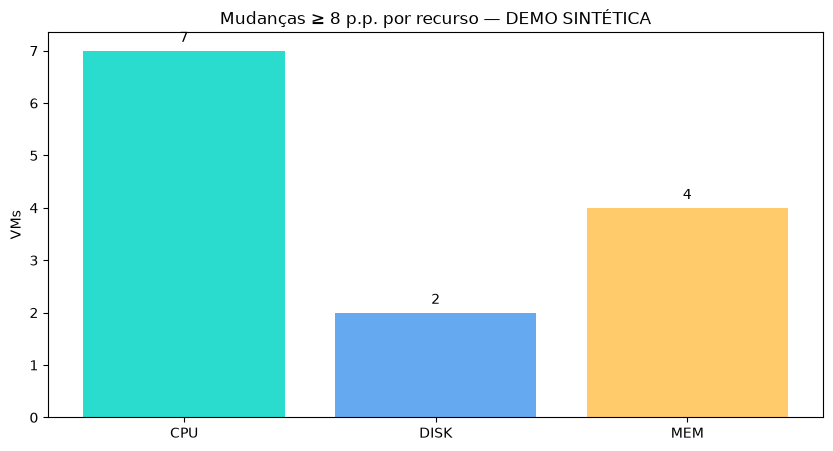

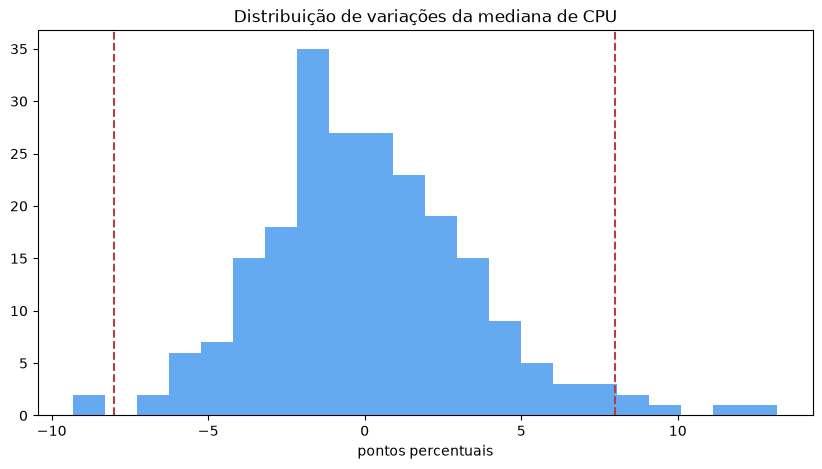

In [4]:
fig,ax=plt.subplots(figsize=(10,5));b=ax.bar(resumo.metrica.str.upper(),resumo.mudancas,color=['#29dccd','#65aaf0','#ffcb6b']);ax.bar_label(b,padding=4);ax.set_title('Mudanças ≥ 8 p.p. por recurso — DEMO SINTÉTICA');ax.set_ylabel('VMs');plt.show()
fig,ax=plt.subplots(figsize=(10,5));ax.hist(validas.loc[validas.metrica=='cpu','delta_pp'],bins=22,color='#65aaf0');ax.axvline(-8,color='#b33f44',ls='--');ax.axvline(8,color='#b33f44',ls='--');ax.set_title('Distribuição de variações da mediana de CPU');ax.set_xlabel('pontos percentuais');plt.show()

## 4. Próximas verificações

Antes de abrir incidente: conferir integridade da coleta, sazonalidade, horas de pico, mudança de workload, implantação recente, criticidade e métricas da aplicação. **Este laboratório não executa alterações em VMs nem comprova drift, causalidade ou degradação.**

In [5]:
saida=root/'graficos';saida.mkdir(exist_ok=True);validas.to_csv(saida/'variacao_metricas_demo.csv',index=False);resumo.to_csv(saida/'resumo_variacao_demo.csv',index=False);print('Arquivos salvos em:',saida)

Arquivos salvos em: /home/francisco/PythonProjects/aiops_capacity_lab/graficos
